In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
type(pd)

module

In [10]:
filename="C:/Users/Dell/Desktop/enso_baja/data/oni_mensual_1981_2026.csv"
type(filename)

str

In [13]:
oni = pd.read_csv(filename, parse_dates=["time"])
# El pd es para leer archivos de texto que estén acomodados como en columnas. Al poner pd.read_csv lo que hace es busca la función 
# read_csv dentro del módulo o paquetería de pandas para leer el archvio.
# Para saber qué funciones tiene pandas, cursor después de pd. y presionar tab

In [16]:
oni

,time,oni_degC
0,1981-09-01,-0.25
1,1981-10-01,-0.16
2,1981-11-01,-0.13
3,1981-12-01,-0.15
4,1982-01-01,-0.08
...,...,...
535,2026-04-01,0.11
536,2026-05-01,0.46
537,2026-06-01,0.95
538,2026-07-01,1.39


In [19]:
type(oni)

pandas.core.frame.DataFrame

In [22]:
oni.shape

(540, 2)

In [25]:
oni.describe()

,time,oni_degC
count,540,540.000000
mean,2004-02-15 08:00:00,0.046185
min,1981-09-01 00:00:00,-1.850000
25%,1992-11-23 12:00:00,-0.552500
50%,2004-02-15 12:00:00,-0.075000
75%,2015-05-08 18:00:00,0.572500
max,2026-08-01 00:00:00,2.750000
std,NaN,0.871231


In [28]:
degC=oni.oni_degC
degC.max()

2.75

In [32]:
degC.min()

-1.85

In [35]:
## Para saber la fecha con el valor más alto de deg
posicion=degC.idxmax()
oni.time[posicion]

Timestamp('2016-01-01 00:00:00')

In [39]:
## Cuántos meses contiene el archivo?
len(oni)

540

In [41]:
imax=oni.oni_degC.idxmax()
imax

412

In [44]:
oni.loc[imax]
# Con loc se pueden meter condiciones como algo mayor que, verdadero o falso

time        2016-01-01 00:00:00
oni_degC                   2.75
Name: 412, dtype: object

In [47]:
oni.oni_degC>0.5

0      False
1      False
2      False
3      False
4      False
       ...  
535    False
536    False
537     True
538     True
539     True
Name: oni_degC, Length: 540, dtype: bool

In [50]:
niño = oni.loc[oni.oni_degC>0.5]
niño

,time,oni_degC
9,1982-06-01,0.66
10,1982-07-01,0.72
11,1982-08-01,0.79
12,1982-09-01,1.07
13,1982-10-01,1.58
...,...,...
511,2024-04-01,1.26
512,2024-05-01,0.82
537,2026-06-01,0.95
538,2026-07-01,1.39


In [53]:
x = -1.2

if x >= 0.5:
    print("niño")
elif x <= -0.5:
    print("niña")
else:
    print("neutral")

niña


In [56]:
def enso_phase(oni_value):
    '''Esta función arroja la fase del ENSO dpendiendo del valor de ONI
    INPUT: oni_value: float
    OUTPUT: phase: str'''
    if oni_value >= 0.5:
        return "El niño"
    elif oni_value <= -0.5:
        return "La niña"
    else:
        return "Neutral"

In [59]:
enso_phase(x)

'La niña'

In [62]:
?enso_phase

Signature: enso_phase(oni_value)
Docstring:
Esta función arroja la fase del ENSO dpendiendo del valor de ONI
INPUT: oni_value: float
OUTPUT: phase: str
File:      c:\users\dell\appdata\local\temp\ipykernel_21016\2397690910.py
Type:      function

In [65]:
values = [1.2, -0.7, 0.0]

for value in values:
    print(value, enso_phase(value))

1.2 El niño
-0.7 La niña
0.0 Neutral


In [68]:
oni["Phase"] = oni.oni_degC.apply(enso_phase)

oni.head(40)

,time,oni_degC,Phase
0,1981-09-01,-0.25,Neutral
1,1981-10-01,-0.16,Neutral
2,1981-11-01,-0.13,Neutral
3,1981-12-01,-0.15,Neutral
4,1982-01-01,-0.08,Neutral
5,1982-02-01,-0.05,Neutral
6,1982-03-01,0.07,Neutral
7,1982-04-01,0.19,Neutral
8,1982-05-01,0.47,Neutral
9,1982-06-01,0.66,El niño


In [71]:
filename1="C:/Users/Dell/Desktop/enso_baja/data/precipitacion_ensenada_1981_2026.csv"
prec = pd.read_csv(filename1, parse_dates=["time"])

In [74]:
prec

,time,precip_mm
0,1981-09-01,2.0
1,1981-10-01,5.0
2,1981-11-01,68.5
3,1981-12-01,20.0
4,1982-01-01,54.8
...,...,...
535,2026-04-01,15.0
536,2026-05-01,17.0
537,2026-06-01,0.0
538,2026-07-01,0.0


In [77]:
prec.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   time       540 non-null    datetime64[ns]
 1   precip_mm  511 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 8.6 KB


In [80]:
prec.isna().sum()

time          0
precip_mm    29
dtype: int64

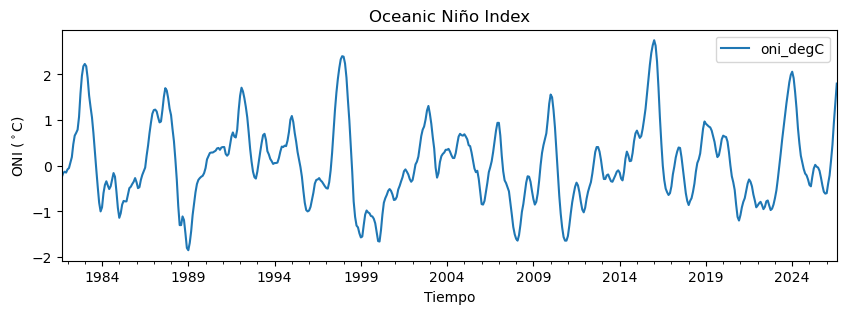

In [83]:
oni.plot(x="time",y="oni_degC",figsize = (10,3))
plt.ylabel(r"ONI ($^\circ$C)")
plt.xlabel("Tiempo")
plt.title('Oceanic Niño Index')
plt.show()

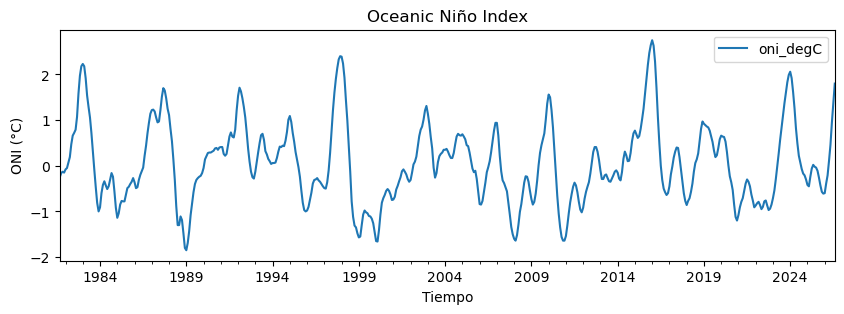

In [86]:
oni.plot(x="time",y="oni_degC",figsize = (10,3))
plt.ylabel("ONI (°C)")
plt.xlabel("Tiempo")
plt.title('Oceanic Niño Index')
plt.show()

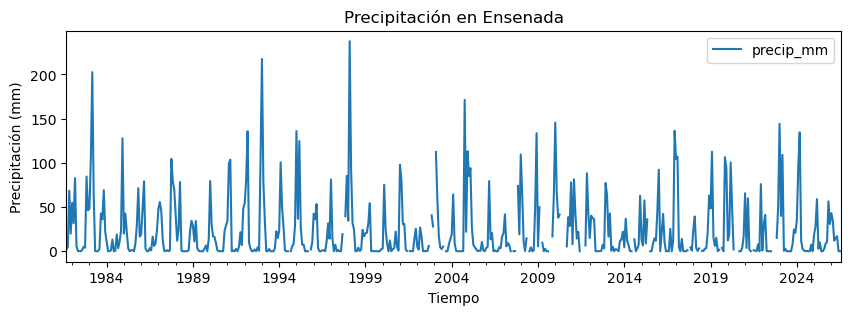

In [89]:
prec.plot(x="time",y="precip_mm",figsize = (10,3))
plt.ylabel("Precipitación (mm)")
plt.xlabel("Tiempo")
plt.title('Precipitación en Ensenada')
plt.show()

In [92]:
relacion=[]

In [95]:
relacion=oni

In [98]:
relacion["PREC"]=prec.precip_mm

In [101]:
relacion

,time,oni_degC,Phase,PREC
0,1981-09-01,-0.25,Neutral,2.0
1,1981-10-01,-0.16,Neutral,5.0
2,1981-11-01,-0.13,Neutral,68.5
3,1981-12-01,-0.15,Neutral,20.0
4,1982-01-01,-0.08,Neutral,54.8
...,...,...,...,...
535,2026-04-01,0.11,Neutral,15.0
536,2026-05-01,0.46,Neutral,17.0
537,2026-06-01,0.95,El niño,0.0
538,2026-07-01,1.39,El niño,0.0


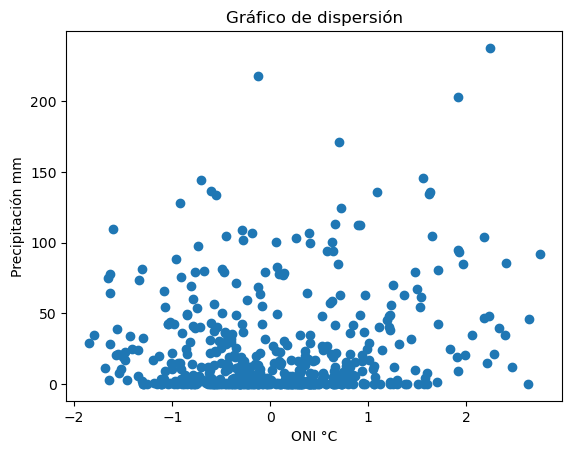

In [119]:
plt.scatter(relacion.iloc[:, 1], relacion.iloc[:, 3])
plt.xlabel("ONI °C")
plt.ylabel("Precipitación mm")
plt.title("Gráfico de dispersión")
plt.show()

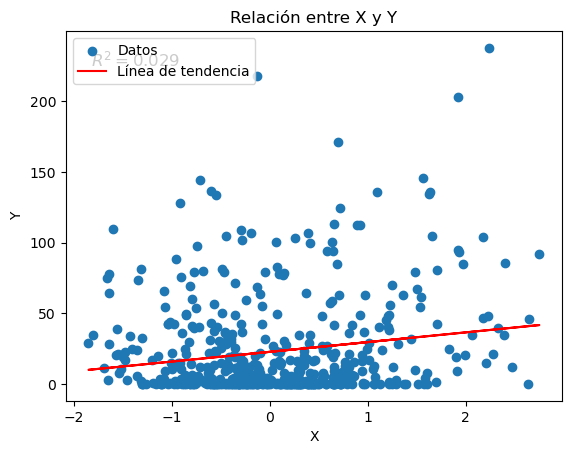

In [110]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

x = relacion.iloc[:, 1]
y = relacion.iloc[:, 3]

# Convertir a arrays y quitar valores vacíos
datos = relacion.iloc[:, [1, 3]].dropna()
x = datos.iloc[:, 0].values
y = datos.iloc[:, 1].values

# Modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(x.reshape(-1, 1), y)

# Predicciones
y_pred = modelo.predict(x.reshape(-1, 1))

# R²
r2 = modelo.score(x.reshape(-1, 1), y)

# Gráfico
plt.scatter(x, y, label="Datos")
plt.plot(x, y_pred, color="red", label="Línea de tendencia")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Relación entre X y Y")

# Mostrar R²
plt.text(
    0.05, 0.95,
    f"$R^2 = {r2:.3f}$",
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top"
)

plt.legend()
plt.show()

In [112]:
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"y = {pendiente:.3f}x + {intercepto:.3f}")
print(f"R² = {r2:.3f}")

y = 6.888x + 22.687
R² = 0.029


In [130]:
yyy = prec.loc[prec.precip_mm==0]
yyy

,time,precip_mm
10,1982-07-01,0.0
20,1983-05-01,0.0
21,1983-06-01,0.0
22,1983-07-01,0.0
29,1984-02-01,0.0
...,...,...
519,2024-12-01,0.0
525,2025-06-01,0.0
526,2025-07-01,0.0
537,2026-06-01,0.0
